# Bloc 3 — Patterns et anomalies
**Fichiers (Public records)** : `officer_filings`, `public_appointments`, `licensed_facilities`, `licensed_professionals`, `institutional_memos`, `public_and_investigative_documents` (versions `_cleaned`).

Pour chaque fichier :
1. **Patterns** : matrice de co-occurrences, itemsets fréquents et règles d'association (Apriori, `mlxtend`) avec *support*, *confidence*, *lift* et *leverage* ;
2. **Anomalies univariées** : IQR, z-score, z-score modifié ;
3. **Anomalies multivariées** : DBSCAN, Isolation Forest, LOF ;
4. **Discussion** : une valeur aberrante est-elle vraiment une anomalie ? On ajoute des **règles logiques** (cohérence des dates) quand les méthodes statistiques ne suffisent pas.

**Rappels de lecture**
- *support* = part des lignes contenant l'itemset ; *confidence* = P(conséquent | antécédent) ; *lift* = confidence / support du conséquent (> 1 : association plus fréquente que le hasard) ; *leverage* = support observé − support attendu si indépendants.
- Un point « aberrant » statistiquement n'est pas forcément une erreur : il peut être rare mais légitime, ou un artefact de génération. On le discute à chaque fois.
- Une anomalie signalée par **plusieurs méthodes différentes** est plus fiable.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from mlxtend.frequent_patterns import apriori, association_rules

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
REF_DATE = pd.Timestamp("2025-12-31")

In [2]:
officers = pd.read_csv("officer_filings_cleaned.csv", parse_dates=["appointment_date", "cessation_date", "filing_date"])
appointments = pd.read_csv("public_appointments_cleaned.csv", parse_dates=["appointment_start", "appointment_end"])
professionals = pd.read_csv("licensed_professionals_cleaned.csv", parse_dates=["license_issue_date"])
memos = pd.read_csv("institutional_memos_cleaned.csv", parse_dates=["document_date"])
documents = pd.read_csv("public_and_investigative_documents_cleaned.csv", parse_dates=["document_date"])
entities = pd.read_csv("registered_entities_cleaned.csv")   # seulement pour le nom des entreprises
reg_name = dict(zip(entities["registration_number"], entities["legal_name"]))

## 0. Fonctions utilitaires (réutilisées pour tous les fichiers)
Mêmes fonctions que dans le notebook du domaine Health, pour que les résultats soient comparables. `patterns` prend ici directement un tableau one-hot (Vrai/Faux), ce qui permet aussi d'utiliser des « paniers » construits à la main (par exemple : une personne = l'ensemble des entreprises où elle a siégé).

In [3]:
def onehot_cat(df_cat):
    # one-hot de chaque modalité ("variable=valeur") : une ligne = un panier d'items
    return pd.get_dummies(df_cat.astype(str), prefix_sep="=", dtype=bool)


# ---------- PATTERNS : co-occurrences + Apriori + règles ----------
def patterns(onehot, min_support, nom, min_conf=0.6, min_lift=1.2, top=12, n_items_heatmap=20):
    # 1) Matrice de co-occurrences (nombre de lignes où deux items apparaissent ensemble)
    frequents = onehot.mean().sort_values(ascending=False).head(n_items_heatmap).index
    X = onehot[frequents].astype(int)
    cooc = X.T @ X
    plt.figure(figsize=(11, 9))
    sns.heatmap(cooc, cmap="Blues", annot=len(frequents) <= 14, fmt="d", cbar_kws={"label": "nombre de co-occurrences"})
    plt.title(f"Matrice de co-occurrences — {nom} ({len(frequents)} items les plus fréquents)")
    plt.tight_layout(); plt.show()

    # 2) Itemsets fréquents (Apriori)
    freq = apriori(onehot, min_support=min_support, use_colnames=True)
    freq["taille"] = freq["itemsets"].apply(len)
    print(f"{len(freq)} itemsets fréquents (support >= {min_support}) dont {(freq.taille >= 2).sum()} de taille >= 2")

    # 3) Règles d'association (num_itemsets requis dans les versions récentes de mlxtend)
    try:
        regles = association_rules(freq, num_itemsets=len(onehot), metric="lift", min_threshold=1.0)
    except TypeError:
        regles = association_rules(freq, metric="lift", min_threshold=1.0)
    regles = regles[(regles.confidence >= min_conf) & (regles.lift >= min_lift)].copy()
    regles["antecedents"] = regles["antecedents"].apply(lambda s: " & ".join(sorted(s)))
    regles["consequents"] = regles["consequents"].apply(lambda s: " & ".join(sorted(s)))
    regles = regles.sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True)
    print(f"{len(regles)} règles avec confidence >= {min_conf} et lift >= {min_lift}")
    cols = ["antecedents", "consequents", "support", "confidence", "lift", "leverage"]
    display(regles[cols].head(top).round(3))
    return regles


# ---------- ANOMALIES UNIVARIEES : IQR, z-score, z-score modifié ----------
def anomalies_univariees(s, nom, unite=""):
    s = s.dropna().astype(float)
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    f_iqr = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)                  # IQR
    z = (s - s.mean()) / s.std()
    f_z = z.abs() > 3                                                    # z-score classique
    med = s.median(); mad = (s - med).abs().median()
    if mad == 0:   # MAD nulle si plus de la moitié des valeurs sont identiques : repli sur l'écart moyen absolu
        zm = (s - med) / (1.253314 * (s - med).abs().mean())
    else:
        zm = 0.6745 * (s - med) / mad
    f_zm = zm.abs() > 3.5                                                # z-score modifié (robuste)
    res = pd.DataFrame({"valeur": s, "z": z.round(2), "z_modifie": zm.round(2), "IQR": f_iqr, "flag_z": f_z, "flag_zm": f_zm})
    print(f"{nom} : n={len(s)}, médiane={med:.2f}, Q1={q1:.2f}, Q3={q3:.2f}, min={s.min():.2f}, max={s.max():.2f}")
    print(f"  bornes IQR : [{q1 - 1.5 * iqr:.1f} ; {q3 + 1.5 * iqr:.1f}]")
    print(f"  IQR : {f_iqr.sum()} | z-score (|z|>3) : {f_z.sum()} | z modifié (>3.5) : {f_zm.sum()}")
    fig, ax = plt.subplots(figsize=(10, 2.8))
    sns.boxplot(x=s, ax=ax, color="lightsteelblue", showfliers=False)
    sns.stripplot(x=s[~f_iqr], ax=ax, color="grey", size=3, alpha=0.5)
    sns.stripplot(x=s[f_iqr], ax=ax, color="crimson", size=5)
    ax.set_title(f"{nom} (rouge = hors IQR)"); ax.set_xlabel(unite)
    plt.tight_layout(); plt.show()
    return res


# ---------- ANOMALIES MULTIVARIEES : DBSCAN, Isolation Forest, LOF ----------
def anomalies_multivariees(X, nom, contamination=0.05, n_voisins=10, min_samples=5):
    Xs = StandardScaler().fit_transform(X)
    iso = IsolationForest(contamination=contamination, random_state=42).fit(Xs)
    f_if = iso.predict(Xs) == -1; s_if = -iso.score_samples(Xs)
    lof = LocalOutlierFactor(n_neighbors=min(n_voisins, len(Xs) - 1), contamination=contamination)
    f_lof = lof.fit_predict(Xs) == -1
    # DBSCAN : eps lu sur la courbe des distances au min_samples-ième voisin (quantile 1 - contamination)
    d, _ = NearestNeighbors(n_neighbors=min_samples).fit(Xs).kneighbors(Xs)
    kdist = np.sort(d[:, -1])
    eps = max(np.quantile(kdist, 1 - contamination), 0.1)
    f_db = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(Xs) == -1
    res = pd.DataFrame({"IsolationForest": f_if, "LOF": f_lof, "DBSCAN": f_db, "score_if": s_if.round(3)}, index=X.index)
    res["nb_methodes"] = res[["IsolationForest", "LOF", "DBSCAN"]].sum(axis=1)
    print(f"{nom} : n={len(X)} | Isolation Forest : {f_if.sum()} | LOF : {f_lof.sum()} | DBSCAN (eps={eps:.2f}, min_samples={min_samples}) : {f_db.sum()}")
    print("  Signalés par >= 2 méthodes :", (res.nb_methodes >= 2).sum(), "| par les 3 :", (res.nb_methodes == 3).sum())
    P = PCA(n_components=2).fit_transform(Xs) if Xs.shape[1] > 2 else Xs
    couleurs = {0: "lightgrey", 1: "gold", 2: "darkorange", 3: "crimson"}
    plt.figure(figsize=(7, 5))
    for k in [0, 1, 2, 3]:
        m = (res.nb_methodes == k).values
        if m.any():
            plt.scatter(P[m, 0], P[m, 1], c=couleurs[k], s=20 if k == 0 else 55, edgecolor="k" if k else "none",
                        linewidth=0.4, label=f"{k} méthode(s) ({m.sum()})")
    plt.legend(title="Signalé par"); plt.title(f"{nom} — anomalies multivariées (projection PCA)")
    plt.tight_layout(); plt.show()
    return res

---
## 1. `officer_filings`
Mêmes variables construites qu'au bloc 1.

In [4]:
of = officers.copy()
of["entity"] = of["registration_number"].map(reg_name)
of["tenure_days"] = (of["cessation_date"] - of["appointment_date"]).dt.days
of["appointment_year"] = of["appointment_date"].dt.year
b = of["birth_year_or_age_band"]
annee_exacte = pd.to_numeric(b.where(b.str.fullmatch(r"\d{4}")), errors="coerce")
of["birth_year_est"] = annee_exacte.fillna(b.str.extract(r"(\d{4})\D+(\d{4})").astype(float).mean(axis=1))
of["age_at_appointment"] = of["appointment_year"] - of["birth_year_est"]
of["tenure_to_ref_days"] = (of["cessation_date"].fillna(REF_DATE) - of["appointment_date"]).dt.days

### 1.1 Patterns (Apriori)
Une **transaction = une personne** ; ses items sont les entreprises où elle a siégé et sa nationalité. Cela permet de voir quelles entreprises **partagent des dirigeants**.

Personnes ayant siégé dans au moins 2 entreprises : 27 / 104
entity                         entity                            
Ardena Capital Union           Horizon Field Research Cooperative    4
Common Ground Climate Forum    Meridian–Asterion Foundation          4
Helix Legal and Compliance     Solvane Energy Group                  4
Meridian BioLogistics          Valenne Industrial Futures Council    4
Nivren Maritime Logistics      Whitehaven Strategic Holdings         4
Northstar Cold Chain Services  Threshold Earth Observatory           4
Ardena Capital Union           Whitehaven Strategic Holdings         1
Nivren Maritime Logistics      Northstar Cold Chain Services         1
Solvane Energy Group           Valenne Industrial Futures Council    1


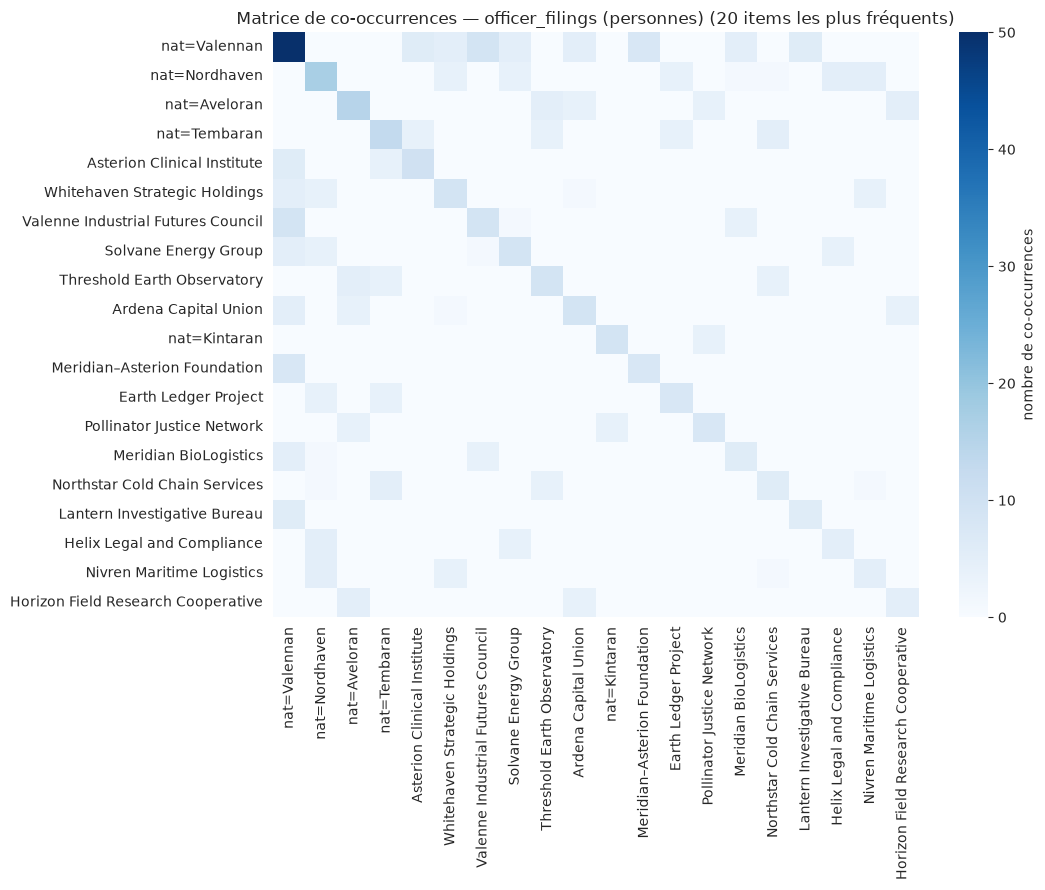

60 itemsets fréquents (support >= 0.03) dont 37 de taille >= 2
40 règles avec confidence >= 0.6 et lift >= 1.2


,antecedents,consequents,support,confidence,lift,leverage
0,Horizon Field Research Cooperative,Ardena Capital Union & nat=Aveloran,0.038,0.800,20.800,0.037
1,Helix Legal and Compliance,Solvane Energy Group & nat=Nordhaven,0.038,0.800,20.800,0.037
2,Nivren Maritime Logistics,Whitehaven Strategic Holdings & nat=Nordhaven,0.038,0.800,20.800,0.037
3,Ardena Capital Union & nat=Aveloran,Horizon Field Research Cooperative,0.038,1.000,20.800,0.037
4,Solvane Energy Group & nat=Nordhaven,Helix Legal and Compliance,0.038,1.000,20.800,0.037
5,Whitehaven Strategic Holdings & nat=Nordhaven,Nivren Maritime Logistics,0.038,1.000,20.800,0.037
6,Threshold Earth Observatory & nat=Tembaran,Northstar Cold Chain Services,0.038,1.000,17.333,0.036
7,Northstar Cold Chain Services,Threshold Earth Observatory & nat=Tembaran,0.038,0.667,17.333,0.036
8,Common Ground Climate Forum,Meridian–Asterion Foundation,0.038,1.000,13.000,0.036
9,Common Ground Climate Forum & nat=Valennan,Meridian–Asterion Foundation,0.038,1.000,13.000,0.036


In [5]:
personne_entreprise = pd.crosstab(of["officer_local_ref"], of["entity"]).clip(upper=1).astype(bool)
nationalite = of.drop_duplicates("officer_local_ref").set_index("officer_local_ref")["nationality_or_region"]
paniers_of = pd.concat([personne_entreprise, pd.get_dummies(nationalite, prefix="nat", prefix_sep="=", dtype=bool)], axis=1)
print("Personnes ayant siégé dans au moins 2 entreprises :", (personne_entreprise.sum(axis=1) >= 2).sum(), "/", len(personne_entreprise))

# dirigeants communs entre entreprises (paires uniquement)
cooc = personne_entreprise.astype(int).T @ personne_entreprise.astype(int)
paires = cooc.where(np.triu(np.ones(cooc.shape, dtype=bool), 1)).stack()
print(paires[paires > 0].sort_values(ascending=False).astype(int).to_string())

regles_of = patterns(paniers_of, min_support=0.03, nom="officer_filings (personnes)")

**Interprétation :** 27 personnes sur 104 ont siégé dans au moins deux entreprises. **Six paires d'entreprises partagent chacune exactement 4 dirigeants** : cette régularité suggère un effet de construction des données, on interprète donc la **nature** des paires plutôt que leur effectif.
- Les règles les plus fortes (lift 17 à 21) reprennent ces paires, associées à une nationalité : Nivren ⇒ Whitehaven & Nordhaven, Helix ⇒ Solvane & Nordhaven, Horizon ⇒ Ardena & Aveloran, Northstar ⇒ Threshold Earth & Tembaran. Puis **Common Ground Climate Forum ⇒ Meridian–Asterion Foundation** (confidence 1, lift 13) : tous les dirigeants passés par la coalition militante sont aussi passés par la fondation du groupe Meridian–Asterion.
- Plusieurs relient des organisations **a priori sans rapport ou opposées** : une coalition militante et la fondation d'un groupe industriel, un cabinet de conformité et une entreprise d'énergie, Meridian et une association de politique industrielle.
- Viennent ensuite des règles « entreprise ⇒ nationalité » (Belen ⇒ Kintaran, Northstar ⇒ Tembaran…) : des filières de recrutement par pays.
- Support faible (≈ 0,04, soit 4 personnes) : ce sont des **pistes à vérifier en réseau (bloc 4)**, pas des lois générales.

### 1.2 Anomalies univariées

Année de nomination : n=135, médiane=1999.00, Q1=1990.00, Q3=2008.50, min=1840.00, max=2026.00
  bornes IQR : [1962.2 ; 2036.2]
  IQR : 5 | z-score (|z|>3) : 4 | z modifié (>3.5) : 5


/home/esrapido/miniconda3/envs/datamining/lib/python3.11/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


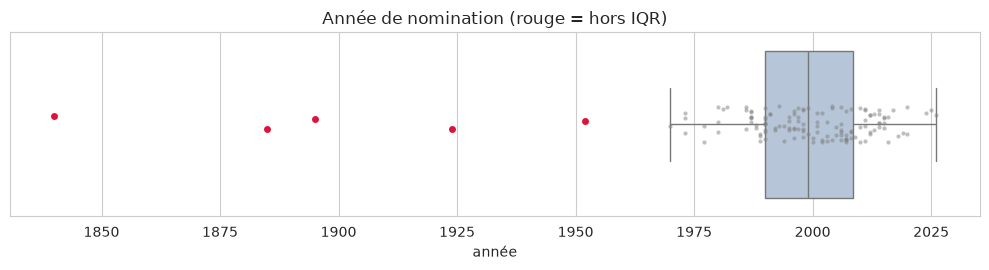

Durée des mandats terminés : n=58, médiane=3286.00, Q1=1460.00, Q3=4290.75, min=-367.00, max=17897.00
  bornes IQR : [-2786.1 ; 8536.9]
  IQR : 7 | z-score (|z|>3) : 2 | z modifié (>3.5) : 5


/home/esrapido/miniconda3/envs/datamining/lib/python3.11/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


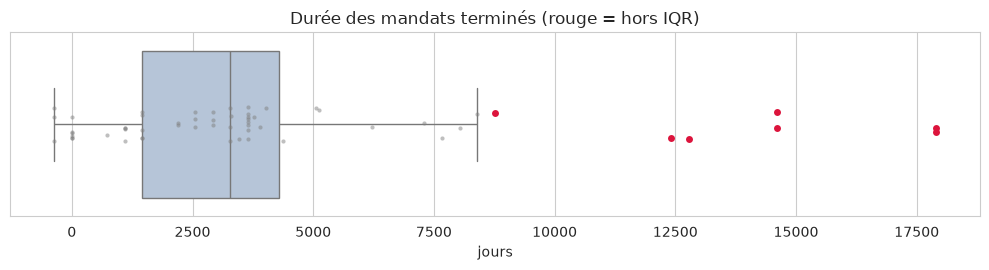

Âge à la nomination : n=135, médiane=27.00, Q1=24.00, Q3=31.00, min=19.50, max=43.50
  bornes IQR : [13.5 ; 41.5]
  IQR : 1 | z-score (|z|>3) : 1 | z modifié (>3.5) : 1


/home/esrapido/miniconda3/envs/datamining/lib/python3.11/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


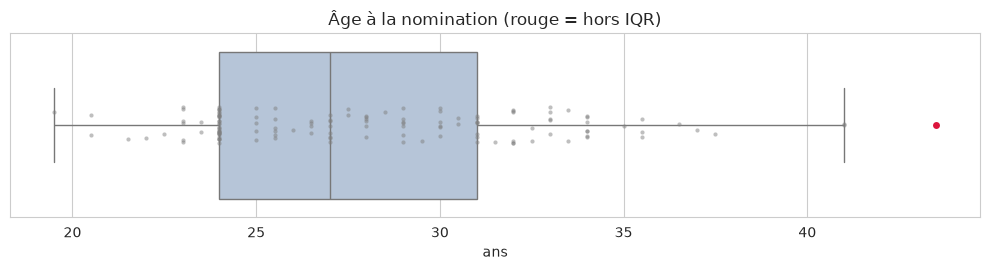

,full_name,entity,appointment_year,IQR,flag_z,flag_zm
0,Edward Vann,Vann Maritime Advisory,1840,True,True,True
1,Emil Warden,Warden Medical Ventures,1895,True,True,True
2,Adrian Vosmere,Vosmere Biotechnics,1952,True,False,True
4,J. Varlan,Varlan Natural History Circle,1885,True,True,True
5,Jonah Bell,Bell Conservation Survey,1924,True,True,True


In [6]:
r_annee = anomalies_univariees(of["appointment_year"], "Année de nomination", "année")
r_duree = anomalies_univariees(of["tenure_days"], "Durée des mandats terminés", "jours")
r_age = anomalies_univariees(of["age_at_appointment"], "Âge à la nomination", "ans")
of.loc[r_annee[r_annee.IQR | r_annee.flag_zm].index, ["full_name", "entity", "appointment_year"]].join(r_annee[["IQR", "flag_z", "flag_zm"]])

**Interprétation :**
- **Année de nomination** : l'IQR et le z-score modifié signalent les **5 nominations antérieures à 1960** (Vann 1840, Varlan 1885, Warden 1895, Bell 1924, Vosmere 1952). Le z-score classique n'en voit que 4 : les valeurs extrêmes gonflent l'écart-type et masquent celle de 1952 (**effet de masque**). Les méthodes robustes sont préférables ici.
- **Durée** : les mêmes personnes ressortent (mandats de 34 à 49 ans), plus Julien Marot (35 ans, nommé en 1970). Les **durées négatives** (jusqu'à −367 jours) **ne sont pas signalées** : la borne basse de l'IQR est à −2 786 jours. Elles sont pourtant impossibles → règle logique en 1.4.
- **Âge** : une seule valeur (Adrienne Solva, 43,5 ans), estimée à partir d'une tranche : signal peu fiable.

### 1.3 Anomalies multivariées
Variables numériques : année de nomination, âge à la nomination, durée du mandat (jusqu'au 31/12/2025 s'il est en cours).

officer_filings : n=135 | Isolation Forest : 7 | LOF : 7 | DBSCAN (eps=1.34, min_samples=5) : 4
  Signalés par >= 2 méthodes : 5 | par les 3 : 4


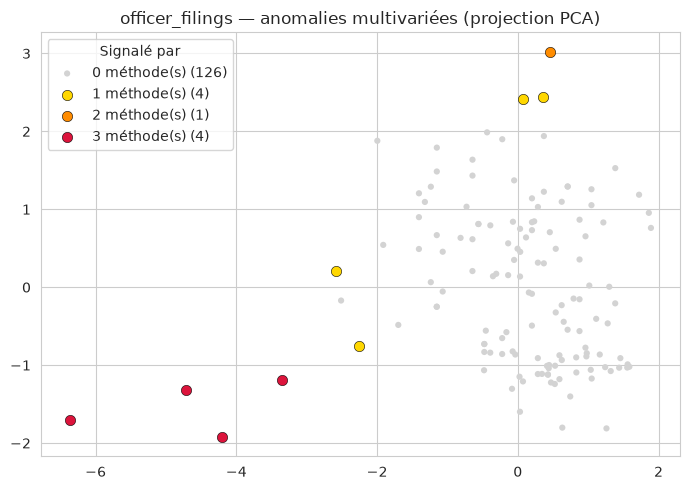

,full_name,entity,appointment_year,age_at_appointment,tenure_to_ref_days,IsolationForest,LOF,DBSCAN,nb_methodes
0,Edward Vann,Vann Maritime Advisory,1840,25.0,17897,True,True,True,3
4,J. Varlan,Varlan Natural History Circle,1885,23.0,12416,True,True,True,3
1,Emil Warden,Warden Medical Ventures,1895,24.0,17895,True,True,True,3
5,Jonah Bell,Bell Conservation Survey,1924,24.0,14609,True,True,True,3
26,Adrienne Solva,Ardena Capital Union,1998,43.5,4017,True,True,False,2


In [7]:
X_of = of[["appointment_year", "age_at_appointment", "tenure_to_ref_days"]]
m_of = anomalies_multivariees(X_of, "officer_filings", contamination=0.05)
of.loc[m_of.index, ["full_name", "entity", "appointment_year", "age_at_appointment", "tenure_to_ref_days"]] \
  .join(m_of[["IsolationForest", "LOF", "DBSCAN", "nb_methodes"]]).query("nb_methodes >= 2").sort_values("appointment_year")

**Interprétation :** Isolation Forest et LOF signalent 7 déclarations, DBSCAN 4. Les **4 nominations les plus anciennes** (Vann 1840, Varlan 1885, Warden 1895, Bell 1924) sont signalées par **les trois méthodes** : ce sont les anomalies les plus fiables du fichier. Adrienne Solva (2 méthodes) ressort par son âge élevé à la nomination, estimé à partir d'une tranche : signal faible.

### 1.4 Discussion : règles logiques
**Durées négatives** : la fin d'un mandat ne peut pas précéder son début.

In [8]:
negatifs = of[of["tenure_days"] < 0]
print(len(negatifs), "mandats à durée négative")
negatifs[["full_name", "nationality_or_region", "entity", "role_title", "appointment_date", "cessation_date", "tenure_days"]]

9 mandats à durée négative


,full_name,nationality_or_region,entity,role_title,appointment_date,cessation_date,tenure_days
35,Calen Uren,Tembaran,Earth Ledger Project,Operations manager,2007-01-01,2006-12-31,-1.0
49,Liora Corda,Tembaran,Asterion Clinical Institute,Regional adviser,2014-01-01,2012-12-31,-366.0
76,Jalen Quorin,Tembaran,Asterion Clinical Institute,Regional adviser,2013-01-01,2011-12-31,-367.0
83,Orin Norel,Valennan,Valenne Industrial Futures Council,Senior analyst,1998-01-01,1997-12-31,-1.0
99,Pavel Waren,Nordhaven,Solvane Energy Group,Programme manager,2011-01-01,2010-12-31,-1.0
123,Elian Cevan,Valennan,Lantern Investigative Bureau,Investigative reporter,2025-01-01,2024-12-31,-1.0
126,Daria Garen,Nordhaven,Solvane Energy Group,Programme manager,2000-01-01,1998-12-31,-366.0
128,Uma Wessen,Aveloran,Ardena Capital Union,Programme manager,2015-01-01,2014-12-31,-1.0
130,Petra Koral,Tembaran,Asterion Clinical Institute,Regional adviser,2005-01-01,2004-12-31,-1.0


9 mandats impossibles, invisibles pour les méthodes statistiques : 6 se terminent la veille de leur début, 3 un an avant. Deux lectures : **erreur de saisie**, ou **antidatage** (déclarer la fin d'un mandat avant une autre fonction, pour qu'elles ne semblent pas se chevaucher). **3 des 9 cas sont des *Regional advisers* tembarans d'Asterion Clinical Institute** (Liora Corda, Jalen Quorin, Petra Koral) : on vérifie en section 2 s'ils occupent une fonction publique.

**Nominations anciennes** : prises une à une, elles sont plausibles. On les met côte à côte avec des dirigeants actuels aux noms et domaines proches.

In [9]:
lignees = {"lignée A (logistique, médical)": ["Edward Vann", "Emil Warden", "Adrian Vosmere", "Dr. Elias Voss"],
           "lignée B (nature, écologie)": ["J. Varlan", "Jonah Bell", "Julien Marot", "Jacob Vale"]}
tables = []
for nom, personnes in lignees.items():
    t = (of[of["full_name"].isin(personnes)].sort_values("appointment_date")
         [["full_name", "birth_year_or_age_band", "entity", "role_title", "appointment_date", "cessation_date"]].copy())
    t["ecart_avec_precedent_ans"] = ((t["appointment_date"] - t["cessation_date"].shift()).dt.days / 365.25).round(1)
    t.insert(0, "lignee", nom)
    tables.append(t)
pd.concat(tables)

,lignee,full_name,birth_year_or_age_band,entity,role_title,appointment_date,cessation_date,ecart_avec_precedent_ans
0,"lignée A (logistique, médical)",Edward Vann,1815,Vann Maritime Advisory,Industrial and shipping adviser,1840-01-01,1888-12-31,NaN
1,"lignée A (logistique, médical)",Emil Warden,1871,Warden Medical Ventures,Commercial and medical investor,1895-01-01,1943-12-31,6.0
2,"lignée A (logistique, médical)",Adrian Vosmere,1920–1929,Vosmere Biotechnics,Biotechnology and logistics executive,1952-01-01,1991-12-31,8.0
3,"lignée A (logistique, médical)",Dr. Elias Voss,1961,Meridian BioLogistics,Executive chair of Meridian BioLogistics,1996-01-01,NaT,4.0
4,"lignée B (nature, écologie)",J. Varlan,1862,Varlan Natural History Circle,Natural-history correspondent,1885-01-01,1918-12-31,NaN
5,"lignée B (nature, écologie)",Jonah Bell,1900,Bell Conservation Survey,Conservation researcher,1924-01-01,1963-12-31,5.0
6,"lignée B (nature, écologie)",Julien Marot,1940–1949,Marot Ecological Policy Office,Environmental-policy adviser,1970-01-01,2004-12-31,6.0
7,"lignée B (nature, écologie)",Jacob Vale,1971,Vale Strategy Collective,Founder and senior adviser of Vale Strategy Co...,2008-01-01,NaT,3.0


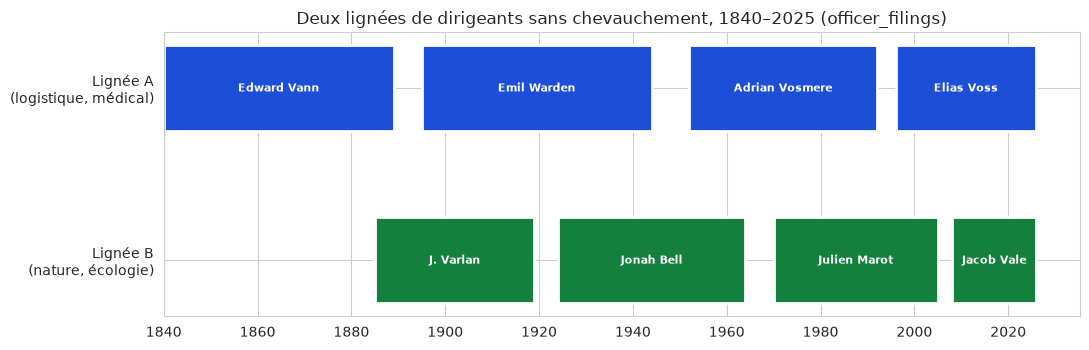

In [10]:
# frise des deux lignées : chaque barre = un mandat ; aucune ne se chevauche
fig, ax = plt.subplots(figsize=(11, 3.6))
couleurs = {"lignée A (logistique, médical)": "#1d4ed8", "lignée B (nature, écologie)": "#15803d"}
lignes = pd.concat(tables).reset_index(drop=True)
for i, r in lignes.iterrows():
    fin = r["cessation_date"] if pd.notna(r["cessation_date"]) else REF_DATE
    y = 1 if r["lignee"].startswith("lignée A") else 0
    ax.barh(y, (fin - r["appointment_date"]).days, left=r["appointment_date"], height=0.5,
            color=couleurs[r["lignee"]], edgecolor="white", linewidth=2)
    ax.text(r["appointment_date"] + (fin - r["appointment_date"]) / 2, y, r["full_name"].replace("Dr. ", ""),
            ha="center", va="center", color="white", fontsize=8, fontweight="bold")
ax.set_yticks([0, 1]); ax.set_yticklabels(["Lignée B\n(nature, écologie)", "Lignée A\n(logistique, médical)"])
ax.set_title("Deux lignées de dirigeants sans chevauchement, 1840–2025 (officer_filings)")
ax.xaxis_date(); plt.tight_layout(); plt.show()

Dans chaque lignée, les mandats se succèdent **sans chevauchement** (écarts de 3 à 8 ans), les **initiales** se répètent (E. V. → E. W. → A. V. → E. V. ; J. V. → J. B. → J. M. → J. V.) et les intitulés « s'additionnent » (*shipping* → *medical investor* → *biotechnology and logistics* → *BioLogistics*). Les entreprises anciennes n'ont qu'un seul dirigeant connu et sont dissoutes.

**Est-ce vraiment une anomalie ?** Beaucoup de carrières du fichier s'enchaînent sans chevauchement : la succession seule ne prouve rien. C'est l'**accumulation** (succession + initiales + domaines) qui interroge → **hypothèse de continuité d'identité** (un même acteur sous plusieurs noms), à confirmer avec les licences (section 4) et les archives.

**Pas des anomalies** : l'âge estimé à partir d'une tranche ; les nationalités peu représentées isolées au bloc 2.

---
## 2. `public_appointments`

In [11]:
ap = appointments.copy()
ap["start_year"] = ap["appointment_start"].dt.year
ap["is_open"] = ap["appointment_end"].isna().astype(int)
ap["duration_years"] = ((ap["appointment_end"].fillna(REF_DATE) - ap["appointment_start"]).dt.days / 365.25).round(1)
ap["age_at_start"] = ap["start_year"] - ap["recorded_birth_year"]


def niveau(titre):
    t = titre.lower()
    if "deputy" in t:
        return 2
    if any(m in t for m in ["head of government", "senior minister", "governor", "council president", "political intermediary"]):
        return 3
    if any(m in t for m in ["minister", "vice-president", "secretary", "director", "commissioner", "coordinator"]):
        return 2
    return 1


ap["rank"] = ap["office_title"].apply(niveau)
pays_institution = {"Avelora": "Aveloran", "Kintara": "Kintaran", "Tembara": "Tembaran", "Orison": "Valennan"}
ap["institution_country"] = ap["institution_name"].apply(lambda s: next(v for k, v in pays_institution.items() if k in s))

### 2.1 Patterns (Apriori)
Items : juridiction de nomination, pays de l'institution, niveau hiérarchique, motif de départ (« en_cours » si le mandat n'est pas terminé). `appointment_basis` (constante) et `official_region` (identique à la juridiction) sont exclues.

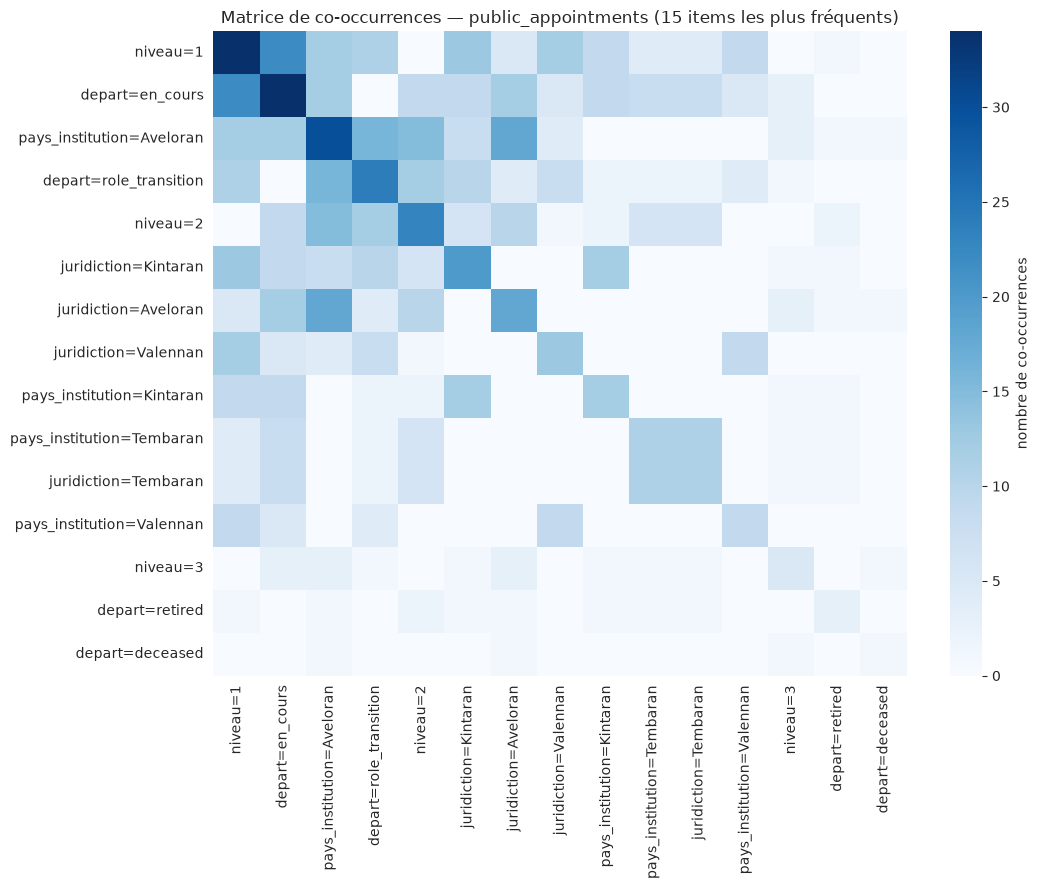

89 itemsets fréquents (support >= 0.05) dont 76 de taille >= 2
109 règles avec confidence >= 0.6 et lift >= 1.2


,antecedents,consequents,support,confidence,lift,leverage
0,niveau=1 & pays_institution=Tembaran,depart=en_cours & juridiction=Tembaran,0.065,1.000,7.750,0.056
1,juridiction=Tembaran & niveau=1,depart=en_cours & pays_institution=Tembaran,0.065,1.000,7.750,0.056
2,depart=en_cours & juridiction=Valennan,pays_institution=Valennan,0.081,1.000,6.889,0.069
3,depart=en_cours & juridiction=Valennan & niveau=1,pays_institution=Valennan,0.081,1.000,6.889,0.069
4,depart=en_cours & juridiction=Valennan,niveau=1 & pays_institution=Valennan,0.081,1.000,6.889,0.069
5,depart=en_cours & juridiction=Kintaran,niveau=1 & pays_institution=Kintaran,0.129,0.889,6.123,0.108
6,niveau=1 & pays_institution=Kintaran,depart=en_cours & juridiction=Kintaran,0.129,0.889,6.123,0.108
7,pays_institution=Tembaran,depart=en_cours & juridiction=Tembaran,0.129,0.727,5.636,0.106
8,juridiction=Tembaran,depart=en_cours & pays_institution=Tembaran,0.129,0.727,5.636,0.106
9,pays_institution=Tembaran,juridiction=Tembaran,0.177,1.000,5.636,0.146


Nominations dans une institution d'un autre pays : 12 / 62
institution_country      Aveloran
appointing_jurisdiction          
Kintaran                        8
Valennan                        4
{'role_transition': 12}


In [12]:
cat_ap = pd.DataFrame({"juridiction": ap["appointing_jurisdiction"], "pays_institution": ap["institution_country"],
                       "niveau": ap["rank"], "depart": ap["departure_reason"].fillna("en_cours")})
regles_ap = patterns(onehot_cat(cat_ap), min_support=0.05, nom="public_appointments")
croise = ap[ap["appointing_jurisdiction"] != ap["institution_country"]]
print("Nominations dans une institution d'un autre pays :", len(croise), "/", len(ap))
print(pd.crosstab(croise["appointing_jurisdiction"], croise["institution_country"]))
print(croise["departure_reason"].value_counts().to_dict())

**Interprétation :** 89 itemsets fréquents et 109 règles, mais les règles de lift élevé sont **mécaniques** : juridiction tembarane ⇔ institution tembarane (confidence 1), agents valennans en cours ⇒ institution valennane… Elles confirment la structure du fichier sans apporter d'indice.

Seul fait notable : **12 nominations sur 62** se font dans une institution d'un autre pays, toutes **en Avelora** (8 Kintarans, 4 Valennans) et toutes terminées par un `role_transition` (postes de passage). Aucun Tembaran ne sert hors de Tembara. Régularité probablement liée à la génération des carrières : notée, pas interprétée.

### 2.2 Anomalies univariées

Durée des mandats : n=62, médiane=14.35, Q1=9.00, Q3=27.25, min=1.00, max=56.70
  bornes IQR : [-18.4 ; 54.6]
  IQR : 1 | z-score (|z|>3) : 0 | z modifié (>3.5) : 1


/home/esrapido/miniconda3/envs/datamining/lib/python3.11/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


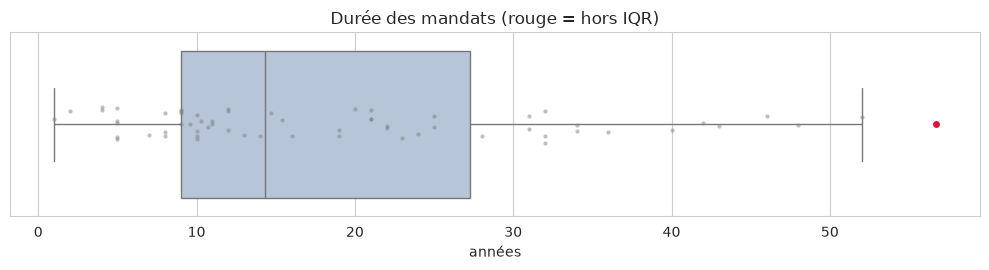

Âge à la nomination : n=56, médiane=28.00, Q1=24.00, Q3=31.00, min=23.00, max=48.00
  bornes IQR : [13.5 ; 41.5]
  IQR : 2 | z-score (|z|>3) : 2 | z modifié (>3.5) : 2


/home/esrapido/miniconda3/envs/datamining/lib/python3.11/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


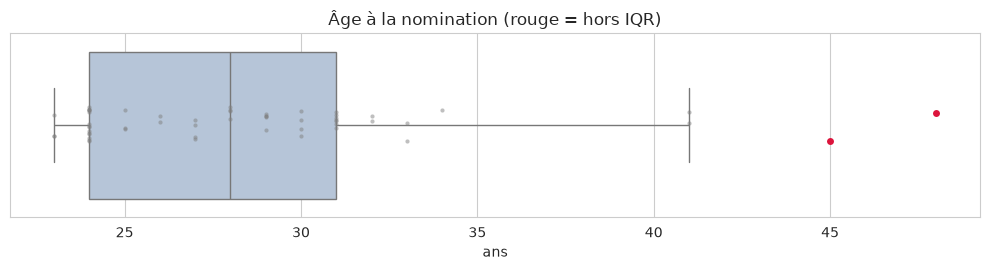

,office_holder_name,office_title,appointment_start,appointment_end,duration_years,departure_reason
5,Elira Vaun,Retired political intermediary and former coun...,1965-01-01,2021-09-18,56.7,deceased


In [13]:
r_dur_ap = anomalies_univariees(ap["duration_years"], "Durée des mandats", "années")
r_age_ap = anomalies_univariees(ap["age_at_start"], "Âge à la nomination", "ans")
ap.loc[r_dur_ap[r_dur_ap.IQR | r_dur_ap.flag_zm].index, ["office_holder_name", "office_title", "appointment_start", "appointment_end", "duration_years", "departure_reason"]]

**Interprétation :**
- **Durée** : une seule valeur hors IQR et z-score modifié, **Elira Vaun** (56,7 ans au conseil d'État aveloran, jusqu'à son décès en 2021). Le z-score classique ne signale rien.
- **Âge à la nomination** : 2 valeurs, Mirek Talven (48 ans) et Elira Vaun (45 ans), nommés tardivement aux plus hauts postes.
- L'univarié voit peu de choses : un gouverneur de 83 ans en poste depuis 52 ans n'est pas « aberrant » statistiquement, mais il l'est au **sens métier**. C'est la combinaison niveau + durée qui compte → multivarié.

### 2.3 Anomalies multivariées

public_appointments : n=62 | Isolation Forest : 5 | LOF : 5 | DBSCAN (eps=1.67, min_samples=4) : 4
  Signalés par >= 2 méthodes : 3 | par les 3 : 2


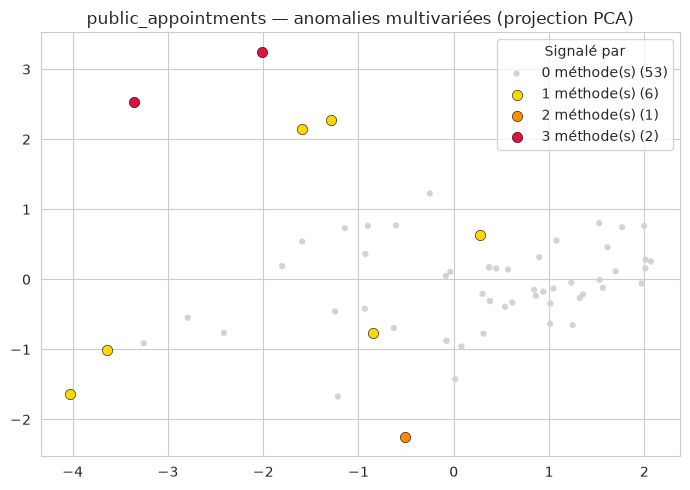

,office_holder_name,office_title,start_year,duration_years,is_open,rank,IsolationForest,LOF,DBSCAN,nb_methodes
57,Jalen Havel,Accreditation officer,1983,43.0,1,1,True,True,False,2
15,Elira Vaun,Council president,1980,19.0,0,3,True,True,True,3
12,Mirek Talven,Deputy regional governor,1990,10.0,0,2,True,True,True,3


In [14]:
X_ap = ap[["start_year", "duration_years", "rank"]].assign(age_at_start=ap["age_at_start"].fillna(ap["age_at_start"].median()))
m_ap = anomalies_multivariees(X_ap, "public_appointments", contamination=0.08, n_voisins=8, min_samples=4)
ap.loc[m_ap.index, ["office_holder_name", "office_title", "start_year", "duration_years", "is_open", "rank"]] \
  .join(m_ap[["IsolationForest", "LOF", "DBSCAN", "nb_methodes"]]).query("nb_methodes >= 2").sort_values("duration_years", ascending=False)

**Interprétation :** Isolation Forest 5, LOF 5, DBSCAN 4 ; 3 nominations signalées par au moins deux méthodes :
- les postes de **Elira Vaun** (présidente du conseil d'État) et **Mirek Talven** (gouverneur adjoint), signalés par les trois méthodes : niveau élevé et nomination ancienne ;
- **Jalen Havel**, agent d'accréditation en poste depuis **43 ans** : durée très longue pour un poste de bas niveau.

Ces signaux pointent vers les **carrières anormalement longues au sommet**, étudiées en 2.4.

### 2.4 Discussion : les « élites persistantes »
Le bloc 1 et les anomalies montrent des personnes **au sommet depuis plusieurs décennies**. On rassemble les postes au sommet de l'État (niveau 3) et les dirigeants d'entreprise dont l'intitulé nomme l'entreprise (*Executive chair of…*, *Chief executive of…* dans `officer_filings`), et on mesure leur ancienneté au poste.

In [15]:
sommet_public = ap[ap["rank"] == 3].rename(columns={"office_holder_name": "nom", "office_title": "fonction",
                                                    "appointment_start": "debut", "appointment_end": "fin"})
sommet_public = sommet_public.assign(source="public_appointments")[["nom", "fonction", "debut", "fin", "source"]]
intitule_long = of["role_title"].str.contains(r"\s(?:of|at)\s", regex=True)
dirigeants = of[intitule_long & (of["filing_status"] == "active")].rename(
    columns={"full_name": "nom", "role_title": "fonction", "appointment_date": "debut", "cessation_date": "fin"})
dirigeants = dirigeants.assign(source="officer_filings")[["nom", "fonction", "debut", "fin", "source"]]

elite = pd.concat([sommet_public, dirigeants], ignore_index=True)
elite["annees_au_poste"] = ((elite["fin"].fillna(REF_DATE) - elite["debut"]).dt.days / 365.25).round(0)
elite = elite.sort_values("annees_au_poste", ascending=False).drop_duplicates("nom")
print({f"> {s} ans": int((elite["annees_au_poste"] > s).sum()) for s in [26, 28, 30, 32, 35, 38, 40]})
elite

{'> 26 ans': 10, '> 28 ans': 9, '> 30 ans': 8, '> 32 ans': 8, '> 35 ans': 8, '> 38 ans': 8, '> 40 ans': 7}


,nom,fonction,debut,fin,source,annees_au_poste
3,Elira Vaun,Retired political intermediary and former coun...,1965-01-01,2021-09-18,public_appointments,57.0
10,Oskar Nivren,Executive chair of Nivren Maritime Logistics,1973-01-01,NaT,officer_filings,53.0
2,Mirek Talven,Regional governor in the Tembara Commonwealth,1974-01-01,NaT,public_appointments,52.0
9,Celene Varro,Chief executive of Solvane Energy Group,1977-01-01,NaT,officer_filings,49.0
0,Leora Kassen,Head of government of Kintara Republic,1978-01-01,NaT,public_appointments,48.0
12,Rayan Belen,Chair of Belen Agro-Industries,1981-01-01,NaT,officer_filings,45.0
1,Tavian Serat,Senior minister of the Avelora Federation,1984-01-01,NaT,public_appointments,42.0
11,Adrienne Solva,Executive director of Ardena Capital Union,1987-01-01,NaT,officer_filings,39.0
5,Dr. Elias Voss,Executive chair of Meridian BioLogistics,1996-01-01,NaT,officer_filings,30.0
8,Soren Kade,Strategic logistics director at Meridian BioLo...,1999-01-01,NaT,officer_filings,27.0


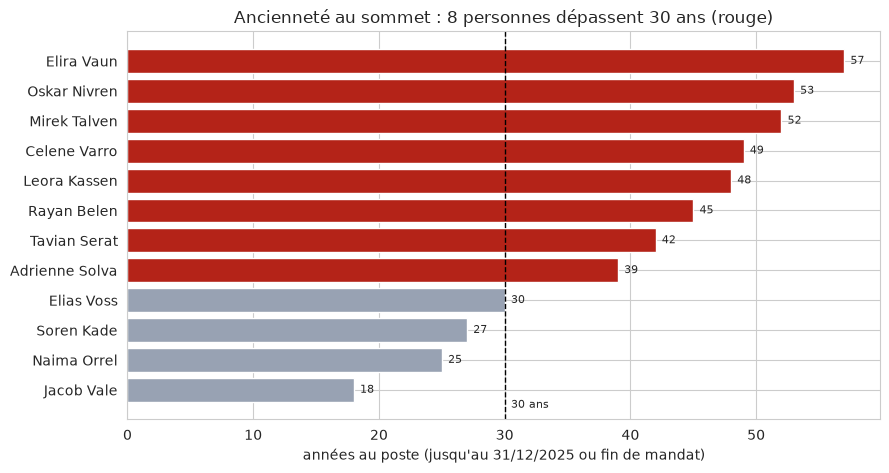

In [26]:
# années au poste des personnes au sommet ; seuil de 30 ans en pointillés
top = elite.sort_values("annees_au_poste")
couleur = np.where(top["annees_au_poste"] > 30, "#b42318", "#98a2b3")
fig, ax = plt.subplots(figsize=(9, 0.32 * len(top) + 1))
ax.barh(top["nom"].str.replace("Dr. ", ""), top["annees_au_poste"], color=couleur)
ax.axvline(30, ls="--", color="k", lw=1); ax.text(30.5, -0.6, "30 ans", fontsize=8)
for y, v in enumerate(top["annees_au_poste"]):
    ax.text(v + 0.5, y, f"{v:.0f}", va="center", fontsize=8)
ax.set_xlabel("années au poste (jusqu'au 31/12/2025 ou fin de mandat)")
ax.set_title("Ancienneté au sommet : 8 personnes dépassent 30 ans (rouge)")
plt.tight_layout(); plt.show()

**Interprétation :** **8 personnes** occupent un poste au sommet depuis **plus de 30 ans** :
- au sommet de l'État : **Elira Vaun** (57 ans, jusqu'à son décès), **Mirek Talven** (52), **Leora Kassen** (48), **Tavian Serat** (42) ;
- à la tête d'entreprises : **Oskar Nivren** (53), **Celene Varro** (49), **Rayan Belen** (45), **Adrienne Solva** (39).

Le résultat est stable : 8 personnes pour tout seuil entre 30 et 38 ans (Elias Voss est à la frontière, avec exactement 30 ans).

**Est-ce vraiment une anomalie ?** Une longue carrière n'a rien d'impossible. Mais 8 dirigeants qui restent au sommet pendant 40 à 57 ans, dans 4 pays et des secteurs différents, est très inhabituel. → **Piste « élites persistantes »**, à croiser avec le dossier **santé** (ces personnes y apparaissent-elles avec des soins récurrents ?).

**Vérification de la piste du 1.4** : les 3 conseillers tembarans d'Asterion à durée négative ont-ils une fonction publique ?

In [27]:
noms = ["Liora Corda", "Jalen Quorin", "Petra Koral"]
asterion = of[of["full_name"].isin(noms)][["full_name", "role_title", "appointment_date", "cessation_date"]]
public = ap[ap["office_holder_name"].isin(noms)][["office_holder_name", "office_title", "institution_name", "appointment_start", "appointment_end"]]
asterion.merge(public, left_on="full_name", right_on="office_holder_name").drop(columns="office_holder_name")

,full_name,role_title,appointment_date,cessation_date,office_title,institution_name,appointment_start,appointment_end
0,Liora Corda,Regional adviser,2014-01-01,2012-12-31,Regional administrative director,Tembara Coastal Administration,2013-01-01,NaT
1,Jalen Quorin,Regional adviser,2013-01-01,2011-12-31,Regional administrative director,Tembara Coastal Administration,2012-01-01,NaT
2,Petra Koral,Regional adviser,2005-01-01,2004-12-31,Regional administrative director,Tembara Coastal Administration,2005-01-01,NaT


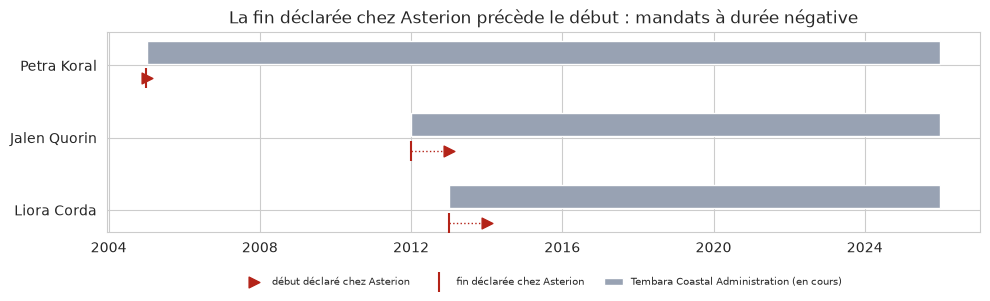

In [37]:
# périodes déclarées : mandat chez Asterion (déclaré) et fonction publique, pour les 3 conseillers
fig, ax = plt.subplots(figsize=(10, 3.2))
for y, nom in enumerate(noms):
    a_ = of[of["full_name"] == nom].iloc[0]
    p_ = ap[ap["office_holder_name"] == nom].iloc[0]
    ax.barh(y + 0.18, (REF_DATE - p_["appointment_start"]).days, left=p_["appointment_start"], height=0.32,
            color="#98a2b3", label="Tembara Coastal Administration (en cours)" if y == 0 else None)
    ax.scatter(a_["appointment_date"], y - 0.18, marker=">", s=60, color="#b42318",
               label="début déclaré chez Asterion" if y == 0 else None, zorder=3)
    ax.scatter(a_["cessation_date"], y - 0.18, marker="|", s=200, color="#b42318",
               label="fin déclarée chez Asterion" if y == 0 else None, zorder=3)
    ax.plot([a_["cessation_date"], a_["appointment_date"]], [y - 0.18, y - 0.18], color="#b42318", lw=1, ls=":")
ax.set_yticks(range(len(noms))); ax.set_yticklabels(noms)
ax.xaxis_date(); ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
ax.set_title("La fin déclarée chez Asterion précède le début : mandats à durée négative")
plt.tight_layout(); plt.show()

**Interprétation :** les trois conseillers d'Asterion sont tous **directeurs administratifs régionaux à la Tembara Coastal Administration**, depuis 2012, 2013 et 2005, toujours en poste.
- Leur mandat chez Asterion est déclaré terminé **exactement la veille** du début de leur fonction publique ;
- pourtant, ce mandat chez Asterion **commence après** (ou le jour même de) leur nomination publique.

Les dates déclarées rendent donc les deux fonctions **non chevauchantes en apparence**, alors qu'elles se chevauchent en réalité. La piste de l'**antidatage** se renforce : un **cumul masqué** entre Asterion (clinique privée) et l'administration tembarane, celle du gouverneur Mirek Talven, l'une des « élites persistantes ».

---
## 3. `licensed_facilities`
**Non traité** : 3 établissements seulement. Ni règles d'association, ni quantiles, ni densité locale n'ont de sens sur 3 lignes. Le fichier sert de référence pour la section 4.

---
## 4. `licensed_professionals`

In [38]:
lp = professionals.copy()
lp["facility"] = lp["primary_facility_license"].fillna("aucun")
lp["issue_year"] = lp["license_issue_date"].dt.year

### 4.1 Patterns (Apriori)

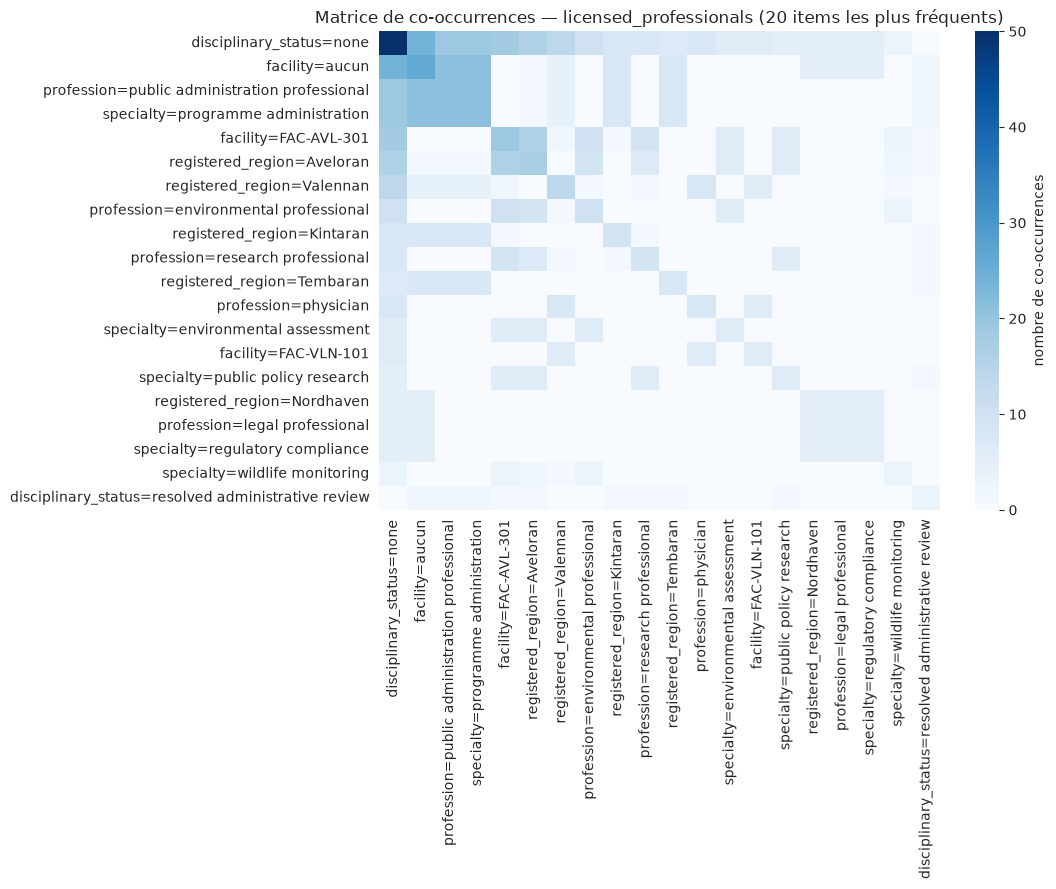

166 itemsets fréquents (support >= 0.05) dont 146 de taille >= 2
481 règles avec confidence >= 0.8 et lift >= 1.2


,antecedents,consequents,support,confidence,lift,leverage
0,profession=legal professional,specialty=regulatory compliance,0.094,1.0,10.6,0.085
1,specialty=regulatory compliance,profession=legal professional,0.094,1.0,10.6,0.085
2,registered_region=Nordhaven,profession=legal professional,0.094,1.0,10.6,0.085
3,profession=legal professional,registered_region=Nordhaven,0.094,1.0,10.6,0.085
4,registered_region=Nordhaven,specialty=regulatory compliance,0.094,1.0,10.6,0.085
5,specialty=regulatory compliance,registered_region=Nordhaven,0.094,1.0,10.6,0.085
6,facility=aucun & profession=legal professional,specialty=regulatory compliance,0.094,1.0,10.6,0.085
7,facility=aucun & specialty=regulatory compliance,profession=legal professional,0.094,1.0,10.6,0.085
8,profession=legal professional,facility=aucun & specialty=regulatory compliance,0.094,1.0,10.6,0.085
9,specialty=regulatory compliance,facility=aucun & profession=legal professional,0.094,1.0,10.6,0.085


In [39]:
cat_lp = lp[["profession", "specialty", "facility", "registered_region", "disciplinary_status"]]
regles_lp = patterns(onehot_cat(cat_lp), min_support=0.05, nom="licensed_professionals", min_conf=0.8)

**Interprétation :** 166 itemsets fréquents et 481 règles (confidence ≥ 0,8), mais les plus fortes sont **définitionnelles** : juriste ⇔ conformité réglementaire ⇔ Nordhaven ⇔ sans établissement (lift 10,6, confidence 1). Elles valident la cohérence du fichier sans révéler d'indice : les profils sont très cloisonnés (cf. bloc 2, silhouette 0,67).

### 4.2 Anomalies univariées

Année de délivrance de la licence : n=53, médiane=2002.00, Q1=1994.00, Q3=2009.00, min=1886.00, max=2026.00
  bornes IQR : [1971.5 ; 2031.5]
  IQR : 5 | z-score (|z|>3) : 2 | z modifié (>3.5) : 3


/home/esrapido/miniconda3/envs/datamining/lib/python3.11/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


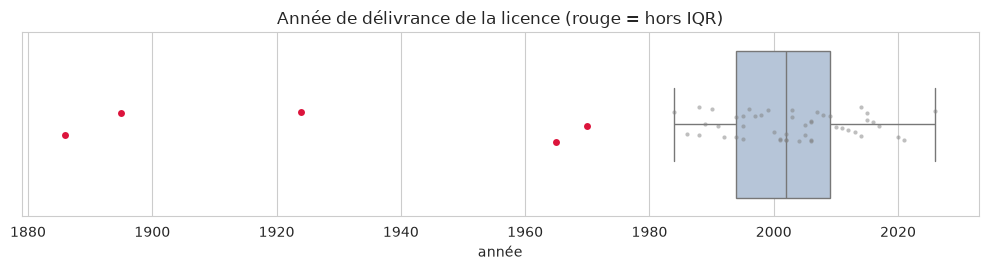

,professional_name,profession,specialty,facility,license_issue_date,license_status
6,J. Varlan,research professional,ecological analytics,FAC-AVL-301,1886-07-01,active
0,Emil Warden,physician,cardiology,FAC-VLN-101,1895-07-01,active
7,Jonah Bell,research professional,public policy research,FAC-AVL-301,1924-07-01,active
12,Elira Vaun,public administration professional,programme administration,aucun,1965-07-01,active
8,Julien Marot,environmental professional,wildlife monitoring,FAC-AVL-301,1970-07-01,active
5,Farah Havel,physician,occupational medicine,FAC-AVL-201,2026-07-01,active


In [40]:
r_lic = anomalies_univariees(lp["issue_year"], "Année de délivrance de la licence", "année")
signales = lp.loc[r_lic[r_lic.IQR | r_lic.flag_zm].index]
futures = lp[lp["license_issue_date"] > REF_DATE]
pd.concat([signales, futures])[["professional_name", "profession", "specialty", "facility", "license_issue_date", "license_status"]].sort_values("license_issue_date")

**Est-ce vraiment une anomalie ?** On croise avec les années de naissance de `officer_filings` pour calculer l'âge des titulaires en 2025.

In [41]:
naissance = of.groupby("full_name")["birth_year_est"].first()
lp["birth_year_est"] = lp["professional_name"].map(naissance)
lp["age_a_la_licence"] = lp["issue_year"] - lp["birth_year_est"]
lp["age_2025"] = REF_DATE.year - lp["birth_year_est"]
print("Professionnels retrouvés dans officer_filings :", lp["birth_year_est"].notna().sum(), "/", len(lp))
lp.dropna(subset=["birth_year_est"]).sort_values("age_2025", ascending=False)[["professional_name", "specialty", "facility", "issue_year", "birth_year_est", "age_a_la_licence", "age_2025"]].head(6)

Professionnels retrouvés dans officer_filings : 42 / 53


,professional_name,specialty,facility,issue_year,birth_year_est,age_a_la_licence,age_2025
6,J. Varlan,ecological analytics,FAC-AVL-301,1886,1862.0,24.0,163.0
0,Emil Warden,cardiology,FAC-VLN-101,1895,1871.0,24.0,154.0
7,Jonah Bell,public policy research,FAC-AVL-301,1924,1900.0,24.0,125.0
8,Julien Marot,wildlife monitoring,FAC-AVL-301,1970,1944.5,25.5,80.5
15,Daria Zaven,general medicine,FAC-VLN-101,1990,1954.5,35.5,70.5
29,Orin Kerin,regulatory compliance,aucun,1988,1956.0,32.0,69.0


**Interprétation :**
- L'IQR signale 5 licences très anciennes (1886, 1895, 1924, 1965, 1970), le z-score modifié 3 et le z-score classique 2 (**effet de masque**). La règle « date future » ajoute **Farah Havel** (licence de juillet 2026).
- Toutes ces licences sont **encore actives**. En croisant avec `officer_filings`, leurs titulaires auraient en 2025 **163 ans** (J. Varlan), **154 ans** (Emil Warden, cardiologue chez Asterion) et **125 ans** (Jonah Bell). Les âges à la délivrance (24 ans) sont, eux, parfaitement normaux : l'anomalie **n'apparaît qu'en croisant deux fichiers**.

**Est-ce vraiment une anomalie ?** Une explication banale existe : des licences jamais radiées. Elle est réelle dans ce registre, puisque la licence d'**Elira Vaun**, décédée en 2021, est toujours active. Mais les licences de Varlan, Warden et Bell sont rattachées à des **établissements ouverts en 2001–2012**, qui n'existaient pas de leur vivant supposé. Ce sont les mêmes noms que les lignées du 1.4 → **appui à l'hypothèse de continuité d'identité**.

### 4.3 Anomalies multivariées
**Non réalisées** : il n'y a qu'**une seule variable numérique** (l'année de délivrance), le reste est nominal. Le multivarié n'apporterait rien de plus que l'univarié. Les profils catégoriels isolés ont déjà été repérés au bloc 2 (DBSCAN en distance de Hamming : les deux médecins de la clinique aveloranne d'Asterion et J. Varlan).

---
## 5. `institutional_memos` et 6. `public_and_investigative_documents`
Le texte lui-même relève du bloc 6. On travaille sur les métadonnées et sur quelques mesures simples :
- `n_words` : longueur ;
- `boilerplate_share` : part des paragraphes qu'on retrouve **mot pour mot dans au moins 3 documents** du corpus (texte « gabarit ») ;
- `n_refs` : nombre de références vers d'autres jeux de données (PO-, SHP-, ADJ-, ACC-, REG-).

In [42]:
from collections import Counter

mem = memos.rename(columns={"visibility_level": "visibility"}).assign(source="memos")
pub = documents.rename(columns={"public_or_restricted": "visibility"}).assign(source="public_docs")
docs = pd.concat([mem, pub], ignore_index=True)
docs["paragraphes"] = docs["text"].apply(lambda t: [p.strip() for p in re.split(r"\n\s*\n", t) if p.strip()])
compte = Counter(p for ps in docs["paragraphes"] for p in set(ps))
docs["n_words"] = docs["text"].str.split().str.len()
docs["boilerplate_share"] = docs["paragraphes"].apply(lambda ps: np.mean([compte[p] >= 3 for p in ps])).round(3)
REF = r"\b(?:PO|SHP|ADJ|ACC|REG)-\d{4}-\d{4,5}\b"
rel = ["related_purchase_order", "related_shipment_number", "related_case_number"]
docs["n_refs"] = [len(set(re.findall(REF, r["text"])) | {x for x in r[rel] if isinstance(x, str)}) for _, r in docs.iterrows()]
docs[["n_words", "boilerplate_share", "n_refs"]].describe().round(2)

,n_words,boilerplate_share,n_refs
count,70.00,70.00,70.00
mean,169.66,0.64,0.39
std,61.53,0.33,0.49
min,82.00,0.00,0.00
25%,122.00,0.44,0.00
50%,141.50,0.78,0.00
75%,218.50,0.88,1.00
max,290.00,1.00,1.00


### 5.1 Patterns (Apriori)

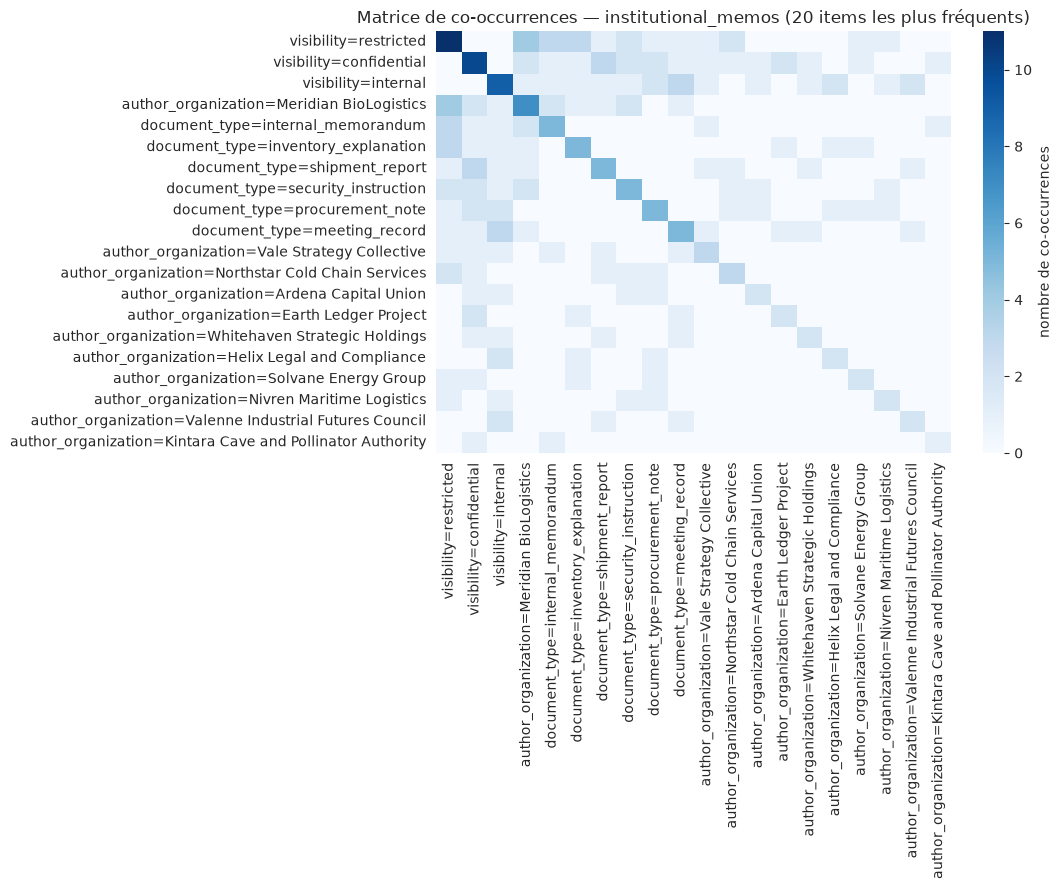

35 itemsets fréquents (support >= 0.05) dont 16 de taille >= 2
8 règles avec confidence >= 0.6 et lift >= 1.2


,antecedents,consequents,support,confidence,lift,leverage
0,author_organization=Helix Legal and Compliance,visibility=internal,0.067,1.000,3.333,0.047
1,author_organization=Valenne Industrial Futures...,visibility=internal,0.067,1.000,3.333,0.047
2,author_organization=Earth Ledger Project,visibility=confidential,0.067,1.000,3.000,0.044
3,document_type=meeting_record,visibility=internal,0.100,0.600,2.000,0.050
4,author_organization=Northstar Cold Chain Services,visibility=restricted,0.067,0.667,1.818,0.030
5,document_type=shipment_report,visibility=confidential,0.100,0.600,1.800,0.044
6,document_type=internal_memorandum,visibility=restricted,0.100,0.600,1.636,0.039
7,document_type=inventory_explanation,visibility=restricted,0.100,0.600,1.636,0.039


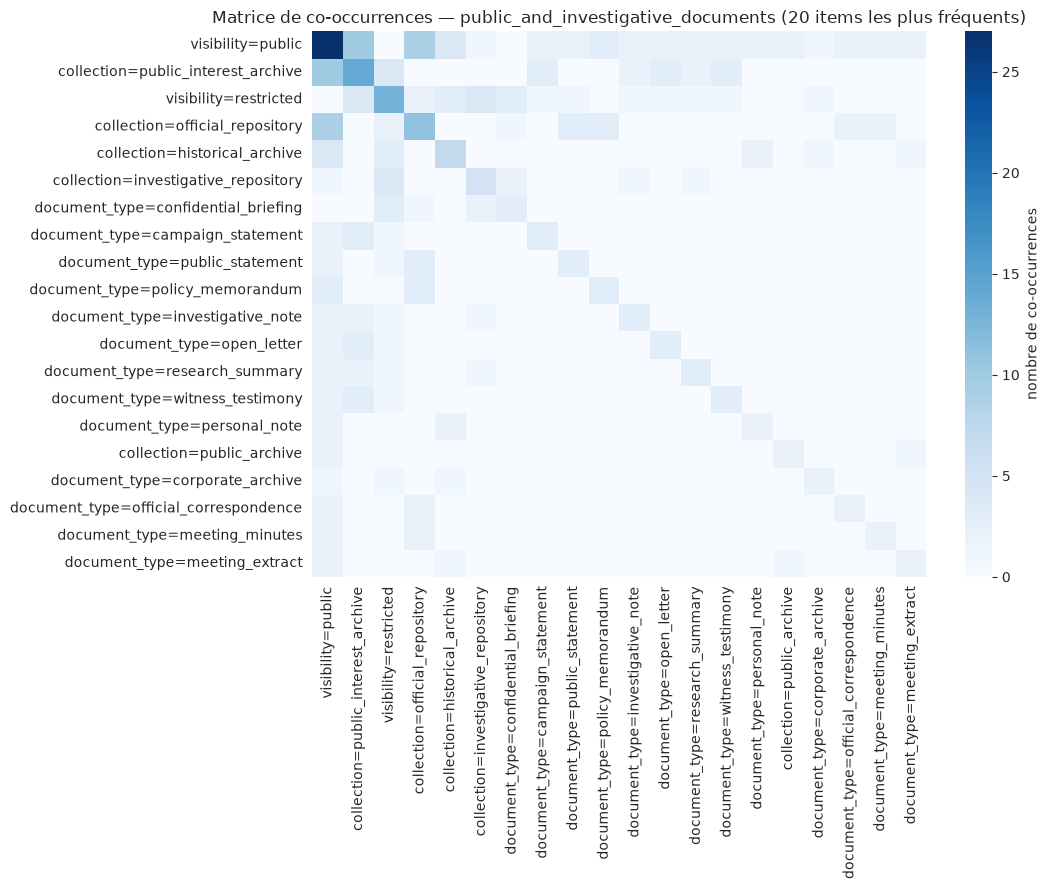

65 itemsets fréquents (support >= 0.05) dont 42 de taille >= 2
47 règles avec confidence >= 0.6 et lift >= 1.2


,antecedents,consequents,support,confidence,lift,leverage
0,document_type=personal_note,collection=historical_archive & visibility=public,0.050,1.000,10.000,0.045
1,document_type=confidential_briefing,collection=investigative_repository & visibili...,0.050,0.667,6.667,0.042
2,document_type=personal_note,collection=historical_archive,0.050,1.000,5.714,0.041
3,document_type=registry_extract,collection=historical_archive,0.050,1.000,5.714,0.041
4,document_type=personal_note & visibility=public,collection=historical_archive,0.050,1.000,5.714,0.041
5,document_type=confidential_briefing,collection=investigative_repository,0.050,0.667,5.333,0.041
6,document_type=confidential_briefing & visibili...,collection=investigative_repository,0.050,0.667,5.333,0.041
7,document_type=meeting_minutes,collection=official_repository & visibility=pu...,0.050,1.000,4.444,0.039
8,document_type=official_correspondence,collection=official_repository & visibility=pu...,0.050,1.000,4.444,0.039
9,document_type=policy_memorandum,collection=official_repository & visibility=pu...,0.075,1.000,4.444,0.058


In [43]:
cat_mem = mem[["document_type", "visibility", "author_organization"]]
regles_mem = patterns(onehot_cat(cat_mem), min_support=0.05, nom="institutional_memos")
cat_pub = pub[["collection", "document_type", "visibility"]]
regles_pub = patterns(onehot_cat(cat_pub), min_support=0.05, nom="public_and_investigative_documents")

**Interprétation :**
- **memos** : 8 règles seulement, de lift modéré (≤ 3,3), du type « organisation ⇒ niveau de visibilité » sur 2 documents (support 0,067). Les memos sont répartis de façon équilibrée : pas de profil typé.
- **documents publics** : 47 règles, essentiellement **définitionnelles** (« type de document ⇒ collection » : les notes personnelles et extraits de registre sont dans les archives historiques, les communiqués dans le dépôt officiel).

Les métadonnées ne révèlent pas de motif caché : l'information est dans le texte (bloc 6).

### 5.2 Anomalies univariées

Longueur des documents : n=70, médiane=141.50, Q1=122.00, Q3=218.50, min=82.00, max=290.00
  bornes IQR : [-22.8 ; 363.2]
  IQR : 0 | z-score (|z|>3) : 0 | z modifié (>3.5) : 0


/home/esrapido/miniconda3/envs/datamining/lib/python3.11/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


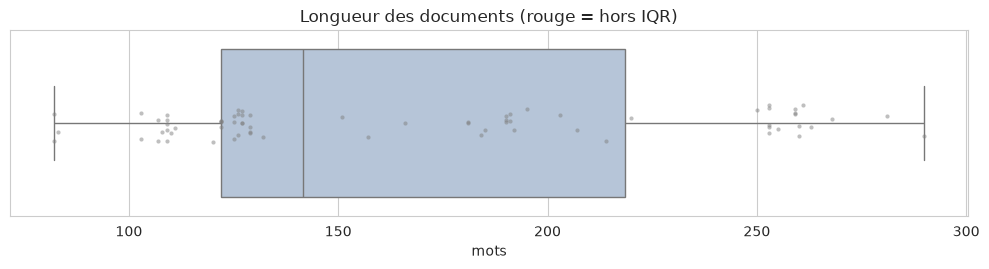

Part de texte gabarit : n=70, médiane=0.78, Q1=0.44, Q3=0.88, min=0.00, max=1.00
  bornes IQR : [-0.2 ; 1.5]
  IQR : 0 | z-score (|z|>3) : 0 | z modifié (>3.5) : 11


/home/esrapido/miniconda3/envs/datamining/lib/python3.11/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


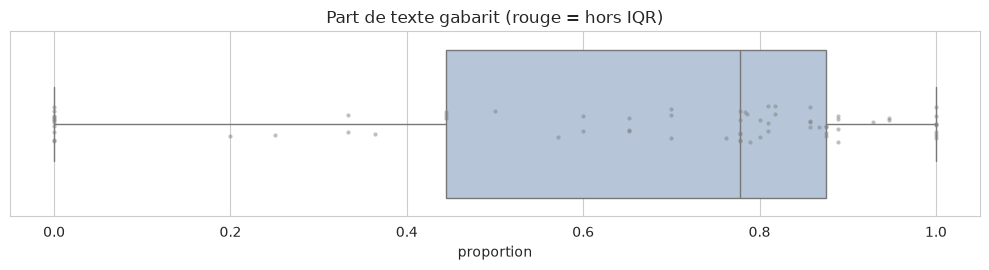

,document_id,document_date,document_type,author_name,author_organization,visibility,n_words
32,PUB-510043,1942-11-06,historical_letter,Emil Warden,Warden Medical Ventures,public,214
33,PUB-510033,1962-05-18,meeting_extract,Jonah Bell,Bell Conservation Survey,public,207
30,PUB-510045,2022-07-08,confidential_briefing,Dr. Lysa Quen,Orison Medical Audit Board,restricted,263
1,MEM-510100,2023-08-17,security_instruction,Soren Kade,Meridian BioLogistics,restricted,166
0,MEM-510062,2024-04-30,inventory_explanation,Soren Kade,Meridian BioLogistics,restricted,185
31,PUB-510094,2024-07-12,research_summary,Selene Aras,Threshold Earth Observatory,public,261
37,PUB-510076,2025-02-05,corporate_archive,Jora Menne,Lantern Investigative Bureau,public,157
34,PUB-510044,2025-02-21,investigative_note,Jora Menne,Lantern Investigative Bureau,restricted,195
2,MEM-510101,2025-03-14,meeting_record,Soren Kade,Meridian BioLogistics,restricted,220
35,PUB-510079,2025-04-09,whistleblower_message,Mara Venn,Lantern Investigative Bureau,restricted,184


In [44]:
r_words = anomalies_univariees(docs["n_words"], "Longueur des documents", "mots")
r_boil = anomalies_univariees(docs["boilerplate_share"], "Part de texte gabarit", "proportion")
docs.loc[r_boil[r_boil.flag_zm].index, ["document_id", "document_date", "document_type", "author_name", "author_organization", "visibility", "n_words"]].sort_values("document_date")

**Interprétation :**
- **Longueur** : aucune anomalie (82 à 290 mots).
- **Texte gabarit** : la distribution est bimodale. L'**IQR et le z-score classique ne signalent rien**, car la borne basse de l'IQR (−0,2) est inatteignable pour une proportion : méthode inadaptée à une variable bornée. Le **z-score modifié isole 11 documents sans aucun texte gabarit** (part = 0).

Ces 11 documents portent **tout le récit** : 3 memos de Meridian signés **Soren Kade** (instruction CHAMELEO, gouvernance CHAMELEO / Unwabu, écart d'inventaire d'« unités biologiques »), le briefing sur les **interventions de santé récurrentes** de l'élite (Dr. Lysa Quen), le message du lanceur d'alerte **Mara Venn** (*Eonycteris spelaea*), et les archives sur les **alias** (Wren Street, lettre de 1942, extrait de réunion de 1962). Les 59 autres sont des variations d'un même gabarit.

**Conséquence pour le bloc 6** : analyser ces 11 documents séparément, ou dédoublonner le texte gabarit avant TF-IDF.

### 5.3 Anomalies multivariées

documents : n=70 | Isolation Forest : 7 | LOF : 7 | DBSCAN (eps=0.84, min_samples=4) : 3
  Signalés par >= 2 méthodes : 4 | par les 3 : 1


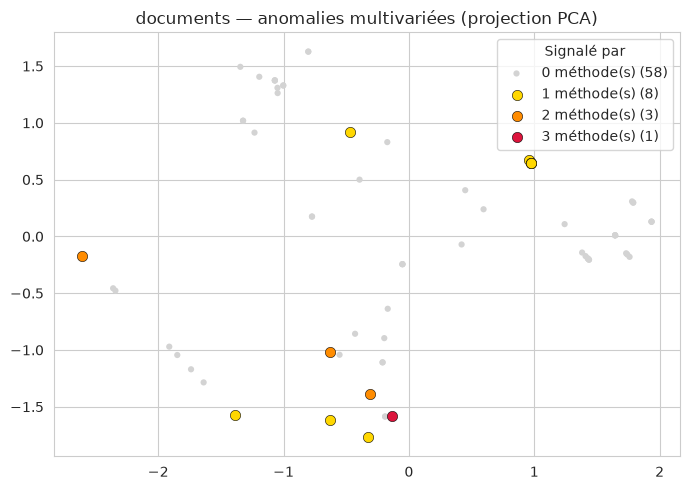

,document_id,document_type,n_words,boilerplate_share,n_refs,IsolationForest,LOF,DBSCAN,nb_methodes
0,MEM-510062,inventory_explanation,185,0.0,1,True,False,True,2
1,MEM-510100,security_instruction,166,0.0,1,True,True,True,3
2,MEM-510101,meeting_record,220,0.0,1,True,False,True,2
36,PUB-510063,confidential_briefing,290,0.0,0,True,True,False,2


In [45]:
m_doc = anomalies_multivariees(docs[["n_words", "boilerplate_share", "n_refs"]], "documents", contamination=0.1, n_voisins=8, min_samples=4)
docs.loc[m_doc.index, ["document_id", "document_type", "n_words", "boilerplate_share", "n_refs"]] \
  .join(m_doc[["IsolationForest", "LOF", "DBSCAN", "nb_methodes"]]).query("nb_methodes >= 2")

**Interprétation :** Isolation Forest 7, LOF 7, DBSCAN 3 ; les 4 documents signalés par au moins deux méthodes font **tous partie des 11 documents sans gabarit** (dont **MEM-510100**, l'instruction CHAMELEO, signalée par les trois). Le multivarié confirme l'univarié sans rien ajouter : une seule variable bien construite (`boilerplate_share`) suffit ici.

### 5.4 Discussion : règle logique sur les auteurs
Un auteur devrait appartenir à l'organisation au nom de laquelle il écrit, à la date du document. On vérifie avec les mandats connus (`officer_filings` et `public_appointments`).

In [46]:
mandats = pd.concat([
    of[["full_name", "entity", "appointment_date", "cessation_date"]].set_axis(["nom", "org", "debut", "fin"], axis=1),
    ap[["office_holder_name", "institution_name", "appointment_start", "appointment_end"]].set_axis(["nom", "org", "debut", "fin"], axis=1)])


def controle_auteur(r):
    m = mandats[(mandats["nom"] == r["author_name"]) & (mandats["org"] == r["author_organization"])]
    if m.empty:
        return "aucun mandat connu"
    dans = ((m["debut"] <= r["document_date"]) & (m["fin"].isna() | (m["fin"] >= r["document_date"]))).any()
    return "ok" if dans else "HORS MANDAT"


docs["controle_auteur"] = docs.apply(controle_auteur, axis=1)
print(docs["controle_auteur"].value_counts().to_dict())
hors = docs[docs["controle_auteur"] == "HORS MANDAT"]
hors.merge(mandats, left_on=["author_name", "author_organization"], right_on=["nom", "org"])[
    ["document_id", "document_date", "document_type", "author_name", "author_organization", "debut", "fin"]]

{'ok': 63, 'HORS MANDAT': 6, 'aucun mandat connu': 1}


,document_id,document_date,document_type,author_name,author_organization,debut,fin
0,MEM-510128,2018-05-15,internal_memorandum,Adrian Vosmere,Vosmere Biotechnics,1952-01-01,1991-12-31
1,MEM-510006,2024-07-04,shipment_report,Nora Essen,Meridian BioLogistics,1997-01-01,2016-12-31
2,MEM-510125,2018-01-19,inventory_explanation,Bela Ferran,Helix Legal and Compliance,2020-01-01,NaT
3,PUB-510005,2020-11-09,public_statement,Sena Grell,Tembara Coastal Administration,2003-01-01,2013-12-31
4,PUB-510104,2018-09-23,public_statement,Gita Aren,Whitehaven Strategic Holdings,1993-01-01,2015-12-31
5,PUB-510023,2021-10-07,whistleblower_message,Miran Zorin,Common Ground Climate Forum,1992-01-01,2015-12-31


**Interprétation :** 6 documents sont signés **hors mandat**.
- Plusieurs sont **anodins** : un ancien employé qui écrit après son départ (Sena Grell, Gita Aren, Miran Zorin, lanceur d'alerte) ; Bela Ferran qui signe pour Helix deux ans avant sa nomination déclarée (retard de déclaration possible).
- Le plus net est **MEM-510128** : un memo opérationnel de **2018** signé **Adrian Vosmere** pour **Vosmere Biotechnics**, alors que son mandat se termine en **1991** et que l'entreprise est **dissoute en 1994** (`registered_entities`). Il porte en plus sur un envoi daté de 2020, deux ans après le memo. → Vosmere est actif bien après sa « fin » : **appui à la piste Vosmere → Voss**.
- MEM-510006 est signé par Nora Essen pour Meridian en 2024, 8 ans après la fin de son mandat : source fragile.